# Salud · DEIS — Resumen Estadístico Mensual (REM)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Data-Observatory/datopia-notebooks/blob/main/salud/deis-rem/demo.ipynb)
[![Licencia](https://img.shields.io/badge/licencia-MIT-blue.svg)](../../LICENSE)
[![Dataset](https://img.shields.io/badge/dataset-DEIS%20REM-green.svg)]()
[![Actualización](https://img.shields.io/badge/actualización-mensual-brightgreen.svg)]()
[![Python](https://img.shields.io/badge/python-3.10%2B-blue.svg)]()

---

## Descripción

Acceso al **Resumen Estadístico Mensual (REM)** del DEIS (Ministerio de Salud de Chile) a través del
**Datopia Lakehouse**: la actividad mensual (consultas, controles, procedimientos, programas) que
reporta cada establecimiento de la red pública, 2009 a hoy.

El dataset tiene dos piezas:

- **Tabla de hechos** (`anio=YYYY/part-*.parquet`): formato largo, una fila por
  (`anio`, `mes`, `id_establecimiento`, `cod_prestacion`, `cod_col_numerica`) con su `cantidad`.
  ~1.900 millones de filas.
- **`codigos-rem`**: el diccionario que traduce los códigos a texto legible (hoja, sección,
  prestación y columna). Pesa unos pocos MB.

El patrón de uso es siempre el mismo: **buscar por texto en `codigos-rem` → elegir la prestación →
filtrar los hechos por esos códigos → sumar**.

### Contenido

1. Configuración y autenticación
2. Exploración del dataset (metadatos, cobertura, diccionario `codigos-rem`)
3. Cómo buscar cualquier dato, paso a paso
4. Caso 1: consultas médicas de salud mental (2017-2025)
5. Caso 2: entrega de leche del PNAC (2017-2025)
6. Tu propia búsqueda

### Requisitos

Cuenta en el Datopia Lakehouse · Python 3.10+ · Las dependencias se instalan automáticamente

In [1]:
# @title Instalación de dependencias
import importlib, subprocess, sys

for paquete in ["requests", "duckdb", "pandas", "matplotlib"]:
    if importlib.util.find_spec(paquete) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", paquete])

import json, os, getpass, pathlib
import requests, duckdb
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

EN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")
pd.set_option("display.max_colwidth", 120)

print("Dependencias listas.")

Dependencias listas.


In [2]:
# @title Configuración de credenciales
print(f"Entorno: {'Google Colab' if EN_COLAB else 'local'}")

URL_API = "https://ee98cnfz7e.execute-api.us-west-2.amazonaws.com/prod"

if EN_COLAB:
    EMAIL = input("Email: ").strip()
    PASSWORD = getpass.getpass("Contraseña: ")
else:
    ruta_cfg = pathlib.Path("../../config.json")
    if not ruta_cfg.exists():
        raise FileNotFoundError(
            f"Archivo de configuración no encontrado en {ruta_cfg.resolve()}.\n"
            "Copia config.example.json → config.json y completa tus credenciales."
        )
    cfg = json.loads(ruta_cfg.read_text())
    EMAIL = cfg.get("test_user", {}).get("email") or input("Email: ").strip()
    PASSWORD = cfg.get("test_user", {}).get("password") or getpass.getpass(
        "Contraseña: "
    )

print(f"API    : {URL_API}")
print(f"Usuario: {EMAIL}")

Entorno: local
API    : https://ee98cnfz7e.execute-api.us-west-2.amazonaws.com/prod
Usuario: do-lakehouse-datopia@dataobservatory.net


---
## 1. Autenticación y conexión a S3

In [3]:
# Iniciar sesión y obtener credenciales temporales S3
resp_login = requests.post(
    f"{URL_API}/auth/login",
    json={"email": EMAIL, "password": PASSWORD},
    timeout=30,
)
resp_login.raise_for_status()
token = resp_login.json()["id_token"]

resp_s3 = requests.post(
    f"{URL_API}/auth/session/s3",
    headers={"Authorization": f"Bearer {token}"},
    timeout=30,
)
resp_s3.raise_for_status()
creds = resp_s3.json()

print("Sesión iniciada")
print(f"  Bucket : {creds['bucket']}")
print(f"  Región : {creds['region']}")
print(f"  Expira : {creds['expires_at']}")

Sesión iniciada
  Bucket : do-datopia
  Región : us-west-2
  Expira : 2026-10-08T15:30:45+00:00


In [4]:
# Configurar DuckDB con credenciales S3
con = duckdb.connect()
con.execute("INSTALL httpfs; LOAD httpfs")
con.execute(f"""
    CREATE OR REPLACE SECRET s3 (
        TYPE          S3,
        KEY_ID        '{creds["access_key_id"]}',
        SECRET        '{creds["secret_access_key"]}',
        SESSION_TOKEN '{creds["session_token"]}',
        REGION        '{creds["region"]}'
    )
""")
con.execute("SET enable_http_metadata_cache=true")
con.execute("SET parquet_metadata_cache=true")
# La lectura remota está limitada por latencia (muchas lecturas pequeñas), no por CPU:
# más hilos de E/S aceleran bastante las consultas sobre la tabla de hechos.
con.execute("SET threads=128")

BASE = (
    f"s3://{creds['bucket']}/categoria=salud/pais=cl/fuente=deis"
    "/tipo=resumen-estadistico-mensual/version=v1"
)

# Vistas para que el SQL de las celdas siguientes se lea limpio
con.execute(f"CREATE OR REPLACE VIEW hechos  AS SELECT * FROM read_parquet('{BASE}/anio=*/part-*.parquet')")
con.execute(f"CREATE OR REPLACE VIEW codigos AS SELECT * FROM read_parquet('{BASE}/codigos-rem/part-*.parquet')")
print("DuckDB conectado a S3. Vistas: hechos, codigos")

DuckDB conectado a S3. Vistas: hechos, codigos


---
## 2. Exploración del dataset

In [5]:
# Metadatos del dataset (dataset.json en la raíz del path S3)
meta = (
    con.execute(f"SELECT * FROM read_json('{BASE}/dataset.json')")
    .df()
    .iloc[0]
    .to_dict()
)

print(meta["description"][:600] + "...")
print()
print(f"Formato     : {meta['format']}")
print(f"Particiones : {list(meta.get('partitioned_by') or meta.get('partition_keys'))}")
print(f"Años        : {list(meta['year_range'])}")

pd.DataFrame([dict(c) for c in meta["columns"]])[["name", "type", "comment"]]

Monthly activity statistics (Resumen Estadistico Mensual, REM) submitted by every public health establishment in Chile to DEIS (Ministry of Health) -- the official national system for tracking primary-care, specialty, and health-program activity across the public network. Unifies five source series (A, BS, BM, D, P -- see tipo_serie) into one long-format table: one row per (anio, mes, id_establecimiento, cod_prestacion, cod_col_numerica). Source: yearly wide-format CSV ZIPs from repositoriodeis.minsal.cl, unpivoted during ETL. cod_prestacion/cod_col_numerica are DEIS's own activity/procedure c...

Formato     : parquet
Particiones : ['anio']
Años        : [np.int64(2009), np.int64(2026)]


,name,type,comment
0,anio,bigint,"Year (Hive partition key, also retained as a column)"
1,mes,tinyint,Month of cod_prestacion cod_col_numerica combination numeric value
2,tipo_serie,string,"Resumen estadistico mensual serie type. Takes a, bs, bm, d or p as value"
3,id_establecimiento,string,Establecimiento de salud id
4,cod_prestacion,string,Id of an specific prestacion in resumen estadistico mensual data
5,cod_col_numerica,string,'colxx' type string that refers to the orignal column names in raw resumen estadistico mensual data
6,cantidad,double,"Reported numeric value for this (id_establecimiento, cod_prestacion, cod_col_numerica) combination"
7,flags_procesamiento,int,Bit-wise flags encoding transformations applied to this row during ETL


In [6]:
# Cobertura: manifest.json lista cada partición anual con su número de filas (no lee datos)
manifest = con.execute(f"SELECT * FROM read_json('{BASE}/manifest.json')").df().iloc[0]
cobertura = pd.DataFrame([dict(p) for p in manifest["parts"]])
cobertura["anio"] = cobertura["file"].str.extract(r"anio=(\d+)").astype(int)
cobertura["MB"] = (cobertura["bytes"] / 1e6).round(0).astype(int)

print(f"Filas totales: {manifest['row_count']:,}")
cobertura[["anio", "row_count", "MB"]].set_index("anio").T

Filas totales: 1,932,539,918


anio,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
row_count,45804699,34794715,53787355,56461721,58214267,74526706,72554507,73740536,109350698,119569136,128900990,110998938,148223228,179529250,201447499,227516749,129614781,107504143
MB,64,55,81,88,90,108,110,114,139,149,160,127,172,204,225,242,148,116


### El diccionario `codigos-rem`

La tabla de hechos solo trae códigos (`cod_prestacion = '04025025'`, `cod_col_numerica = 'col01'`).
`codigos-rem` los traduce, **por año**, siguiendo la jerarquía del formulario REM:

```
cod_hoja / nombre_hoja                  el formulario    (p. ej. a04 "consultas y otras atenciones en la red")
 └ nombre_seccion                       un bloque dentro del formulario
    └ cod_prestacion / nombre_prestacion la fila          (qué se cuenta)
       └ cod_col_numerica / nombre_col_numerica  la columna  (el corte: total, sexo, edad...)
```

Las etiquetas tienen formato `dimensión| valor`, y si combinan varias dimensiones van separadas por
`;` (p. ej. `tipo de conteo| total; sexo| ambos sexos`). La clave para unir con los hechos es
(`anio`, `cod_prestacion`, `cod_col_numerica`).

In [7]:
con.sql("""
    SELECT anio, cod_hoja, nombre_hoja, nombre_seccion, nombre_prestacion, cod_prestacion,
           cod_col_numerica, nombre_col_numerica
    FROM codigos
    WHERE anio = 2024 AND cod_prestacion = '04025025'
    ORDER BY cod_col_numerica
    LIMIT 5
""").df()

,anio,cod_hoja,nombre_hoja,nombre_seccion,nombre_prestacion,cod_prestacion,cod_col_numerica,nombre_col_numerica
0,2024,a04,consultas y otras atenciones en la red,consultas médicas,tipo de atención| salud mental,04025025,col01,tipo de conteo| total; sexo| ambos sexos
1,2024,a04,consultas y otras atenciones en la red,consultas médicas,tipo de atención| salud mental,04025025,col02,tipo de conteo| total; sexo| hombres
2,2024,a04,consultas y otras atenciones en la red,consultas médicas,tipo de atención| salud mental,04025025,col03,tipo de conteo| total; sexo| mujeres
3,2024,a04,consultas y otras atenciones en la red,consultas médicas,tipo de atención| salud mental,04025025,col04,edad| menor de 1 año; sexo| hombres
4,2024,a04,consultas y otras atenciones en la red,consultas médicas,tipo de atención| salud mental,04025025,col05,edad| menor de 1 año; sexo| mujeres


---
## 3. Cómo buscar cualquier dato, paso a paso

No hace falta conocer ningún código. Se parte de una **palabra** y se baja por el árbol del
formulario hasta llegar a la serie. Las funciones de esta sección sirven para cualquier búsqueda;
las secciones 4 y 5 las usan con dos casos concretos.

| Paso | Pregunta | Función | Lee |
|---|---|---|---|
| 1 | ¿En qué hojas y secciones aparece la palabra? | `buscar(texto)` | `codigos` (rápido) |
| 2 | ¿Qué prestaciones hay en esa hoja/sección? | `prestaciones(cod_hoja, ...)` | `codigos` (rápido) |
| 3 | ¿Qué cortes (columnas) trae la prestación? | `columnas_de(cod_hoja, seccion, ...)` | `codigos` (rápido) |
| 4 | ¿Para qué años existe? | `anios_disponibles(cod_hoja, seccion, ...)` | `codigos` (rápido) |
| 5 | Traer los datos | `serie(cod_hoja, seccion, ...)` | `hechos` (1-2 min) |

Los pasos 1 a 4 solo leen el diccionario (pocos MB); recién el paso 5 toca la tabla de hechos.

**Consejo:** filtrar la hoja por `cod_hoja` (estable) y no por `nombre_hoja`: DEIS renombra hojas y
secciones entre años.

In [8]:
def buscar(texto, anio=2024):
    """Paso 1: hojas y secciones donde aparece `texto` (en la hoja, la sección o la prestación)."""
    return con.execute(
        """
        SELECT cod_hoja, nombre_hoja, nombre_seccion,
               COUNT(DISTINCT cod_prestacion) AS coincidencias,
               MIN(nombre_prestacion)         AS ejemplo
        FROM codigos
        WHERE anio = ?
          AND (nombre_hoja ILIKE ? OR nombre_seccion ILIKE ? OR nombre_prestacion ILIKE ?)
        GROUP BY ALL
        ORDER BY cod_hoja, nombre_seccion
        """,
        [anio] + [f"%{texto}%"] * 3,
    ).df()


def prestaciones(cod_hoja, texto=None, seccion=None, anio=2024):
    """Paso 2: prestaciones (filas del formulario) de una hoja, opcionalmente filtradas."""
    return con.execute(
        """
        SELECT DISTINCT nombre_seccion, nombre_prestacion, cod_prestacion
        FROM codigos
        WHERE anio = ? AND cod_hoja = ?
          AND (? IS NULL OR nombre_prestacion ILIKE ?)
          AND (? IS NULL OR nombre_seccion = ?)
        ORDER BY nombre_seccion, nombre_prestacion
        """,
        [anio, cod_hoja, texto, f"%{texto}%", seccion, seccion],
    ).df()


def _filtro(cod_hoja, seccion, prestacion):
    """WHERE común de los pasos 3-5: hoja + sección, y la prestación si se indica (None = todas)."""
    return (
        "cod_hoja = ? AND nombre_seccion = ? AND (? IS NULL OR nombre_prestacion = ?)",
        [cod_hoja, seccion, prestacion, prestacion],
    )


def columnas_de(cod_hoja, seccion, prestacion=None, anio=2024):
    """Paso 3: cortes disponibles (columnas) y cuántas columnas usa cada combinación de dimensiones."""
    where, params = _filtro(cod_hoja, seccion, prestacion)
    cols = con.execute(
        f"""
        SELECT DISTINCT cod_col_numerica, nombre_col_numerica
        FROM codigos WHERE anio = ? AND {where}
        ORDER BY cod_col_numerica
        """,
        [anio] + params,
    ).df()
    # La parte antes de '|' de cada etiqueta es la dimensión
    cols["dimensiones"] = cols["nombre_col_numerica"].map(
        lambda e: ", ".join(p.split("|")[0] for p in e.split("; "))
    )
    return cols


def anios_disponibles(cod_hoja, seccion, prestacion=None):
    """Paso 4: años en que existe la hoja/sección/prestación, con cuántos códigos y columnas."""
    where, params = _filtro(cod_hoja, seccion, prestacion)
    return con.execute(
        f"""
        SELECT anio,
               COUNT(DISTINCT cod_prestacion)   AS prestaciones,
               COUNT(DISTINCT cod_col_numerica) AS columnas
        FROM codigos WHERE {where}
        GROUP BY anio ORDER BY anio
        """,
        params,
    ).df()


def serie(cod_hoja, seccion, prestacion=None, desde=2017, hasta=2025):
    """Paso 5: suma nacional por mes, prestación y columna.

    Primero arma la lista de códigos en `codigos` y luego filtra `hechos` por partición (anio) y por
    cod_prestacion, para no leer el resto de la tabla.

    El cruce de cod_prestacion no distingue mayúsculas: en v1 `codigos` guarda los códigos con
    letras en minúscula (p4180300) y `hechos` en mayúscula (P4180300), p. ej. toda la serie P.
    """
    where, params = _filtro(cod_hoja, seccion, prestacion)
    llaves = con.execute(
        f"""
        SELECT anio, cod_prestacion, cod_col_numerica, nombre_prestacion, nombre_col_numerica
        FROM codigos WHERE anio BETWEEN ? AND ? AND {where}
        """,
        [desde, hasta] + params,
    ).df()
    con.register("llaves", llaves)
    llaves["cod_prestacion"] = llaves["cod_prestacion"].str.lower()
    codigos = llaves["cod_prestacion"].unique()
    codigos_sql = ", ".join(f"'{c}'" for c in set(codigos) | {c.upper() for c in codigos})
    df = con.execute(f"""
        SELECT h.anio, h.mes, l.nombre_prestacion, l.nombre_col_numerica,
               SUM(h.cantidad) AS cantidad
        FROM hechos h
        JOIN llaves l
          ON  h.anio = l.anio
          AND lower(h.cod_prestacion) = l.cod_prestacion
          AND h.cod_col_numerica = l.cod_col_numerica
        WHERE h.anio BETWEEN {desde} AND {hasta}
          AND h.cod_prestacion IN ({codigos_sql})
        GROUP BY ALL
    """).df()
    con.unregister("llaves")
    df["fecha"] = pd.to_datetime(dict(year=df["anio"], month=df["mes"], day=1))
    return df.sort_values(["fecha", "nombre_prestacion", "nombre_col_numerica"]).reset_index(drop=True)


miles = FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", "."))
print("Funciones listas: buscar, prestaciones, columnas_de, anios_disponibles, serie")

Funciones listas: buscar, prestaciones, columnas_de, anios_disponibles, serie


---
## 4. Caso 1: consultas médicas de salud mental

Pregunta: **¿cuántas consultas médicas de salud mental hay en Chile cada mes?**

### Paso 1: ¿dónde aparece "salud mental"?

In [9]:
buscar("salud mental")

,cod_hoja,nombre_hoja,nombre_seccion,coincidencias,ejemplo
0,a03,aplicación y resultados de escalas de evaluación,aplicación de tamizaje para evaluar riesgo de trastornos o problemas de salud mental en aps,10,tipo de método| escala de columbia
1,a04,consultas y otras atenciones en la red,consultas de profesionales no médicos,1,funcionario| trabajador/a social (excluye salud mental)
2,a04,consultas y otras atenciones en la red,consultas médicas,1,tipo de atención| salud mental
3,a05,ingresos y egresos por condición y problemas de salud,egresos del programa de salud mental por altas clínicas en aps /especialidad,44,motivo de egreso| abuso sexual
4,a05,ingresos y egresos por condición y problemas de salud,ingresos al programa de salud mental en aps/especialidad,44,motivo de ingreso| abuso sexual
5,a06,programa de salud mental atención primaria y especialidades,consulta de salud mental por el nivel de especialidad,3,tipo de consulta| consulta nueva salud mental (ingreso); funcionario| dos profesionales
6,a06,programa de salud mental atención primaria y especialidades,evaluaciones programa plan nacional de demencia,3,tipo de consulta| cuidadores de personas con demencia con evaluación de satisfacción usuaria del proceso de interven...
7,a06,programa de salud mental atención primaria y especialidades,evaluación programa de apoyo a la salud mental infantil (pasmi),1,tipo de consulta| evaluación diagnóstica integral (edi)
8,a06,programa de salud mental atención primaria y especialidades,planes y evaluaciones programa de acompañamiento psicosocial en atención primaria,3,tipo de consulta| evaluaciones participativas realizadas al egreso del programa
9,a06,programa de salud mental atención primaria y especialidades,rescate de pacientes programa salud mental,8,edad| 1-4 años


Aparece en muchas hojas: el programa de salud mental, atención remota, visitas, educación... La
pregunta es por **consultas**, así que la rama que interesa es la hoja **a04** (*consultas y otras
atenciones en la red*).

### Paso 2: ¿qué prestaciones de la hoja a04 mencionan salud mental?

In [10]:
prestaciones("a04", texto="salud mental")

,nombre_seccion,nombre_prestacion,cod_prestacion
0,consultas de profesionales no médicos,funcionario| trabajador/a social (excluye salud mental),03020806
1,consultas médicas,tipo de atención| salud mental,04025025


Ojo con el falso positivo: `trabajador/a social (excluye salud mental)` contiene el texto pero
significa lo contrario. La prestación buscada es **`tipo de atención| salud mental`**, sección
**consultas médicas**. Se guarda la elección en tres variables:

In [11]:
SM_HOJA = "a04"
SM_SECCION = "consultas médicas"
SM_PRESTACION = "tipo de atención| salud mental"

### Paso 3: ¿qué cortes trae?

In [12]:
cols_sm = columnas_de(SM_HOJA, SM_SECCION, SM_PRESTACION)
print(cols_sm["dimensiones"].value_counts().to_string())
cols_sm.head(8)

dimensiones
edad, sexo              36
tipo de conteo, sexo     3
grupo poblacional        3
etnia                    1
tipo de atención         1


,cod_col_numerica,nombre_col_numerica,dimensiones
0,col01,tipo de conteo| total; sexo| ambos sexos,"tipo de conteo, sexo"
1,col02,tipo de conteo| total; sexo| hombres,"tipo de conteo, sexo"
2,col03,tipo de conteo| total; sexo| mujeres,"tipo de conteo, sexo"
3,col04,edad| menor de 1 año; sexo| hombres,"edad, sexo"
4,col05,edad| menor de 1 año; sexo| mujeres,"edad, sexo"
5,col06,edad| 1-4 años; sexo| hombres,"edad, sexo"
6,col07,edad| 1-4 años; sexo| mujeres,"edad, sexo"
7,col08,edad| 5-9 años; sexo| hombres,"edad, sexo"


Hay **total y sexo** (3 columnas), **edad × sexo** (36 columnas: 18 tramos) y algunas poblaciones
especiales (pueblos originarios, migrantes...).

### Paso 4: ¿para qué años existe?

In [13]:
anios_disponibles(SM_HOJA, SM_SECCION, SM_PRESTACION)

,anio,prestaciones,columnas
0,2017,1,42
1,2018,1,43
2,2019,1,44
3,2020,1,44
4,2021,1,44
5,2022,1,44
6,2023,1,44
7,2024,1,44
8,2025,1,44


Existe de **2017 a 2025** con un único código por año. (La hoja a04 se llamaba distinto en 2017,
*consultas y otras atenciones* sin "en la red": filtrar por `cod_hoja` evita perder ese año.)

### Paso 5: traer la serie

Una sola consulta trae todas las columnas de la prestación, 2017-2025. Recorre 9 años de la tabla
de hechos desde S3: **toma 1-2 minutos**.

In [14]:
salud_mental = serie(SM_HOJA, SM_SECCION, SM_PRESTACION, desde=2017, hasta=2025)
print(f"Filas: {len(salud_mental):,} (mes × columna)")
salud_mental.head()

Filas: 4,706 (mes × columna)


,anio,mes,nombre_prestacion,nombre_col_numerica,cantidad,fecha
0,2017,1,tipo de atención| salud mental,edad| 1-4 años; sexo| hombres,30.0,2017-01-01
1,2017,1,tipo de atención| salud mental,edad| 1-4 años; sexo| mujeres,32.0,2017-01-01
2,2017,1,tipo de atención| salud mental,edad| 10-14 años; sexo| hombres,139.0,2017-01-01
3,2017,1,tipo de atención| salud mental,edad| 10-14 años; sexo| mujeres,153.0,2017-01-01
4,2017,1,tipo de atención| salud mental,edad| 15-19 años; sexo| hombres,148.0,2017-01-01


### Serie mensual nacional, total y por sexo

In [15]:
SEXOS = {
    "tipo de conteo| total; sexo| ambos sexos": "Total",
    "tipo de conteo| total; sexo| mujeres": "Mujeres",
    "tipo de conteo| total; sexo| hombres": "Hombres",
}
por_sexo = (
    salud_mental[salud_mental["nombre_col_numerica"].isin(SEXOS)]
    .assign(sexo=lambda d: d["nombre_col_numerica"].map(SEXOS))
    .pivot(index="fecha", columns="sexo", values="cantidad")[list(SEXOS.values())]
)

# Totales anuales y meses con dato (2021 trae decimales en origen, de ahí el round)
anual = por_sexo.groupby(por_sexo.index.year).sum().round().astype(int)
anual["meses"] = por_sexo.groupby(por_sexo.index.year).size()
anual

sexo,Total,Mujeres,Hombres,meses
fecha,,,,
2017,188225,133556,54669,12
2018,228352,161387,66964,12
2019,244320,169867,74453,12
2020,171674,121069,50606,12
2021,218263,154155,64108,12
2022,276065,194353,81712,12
2023,323950,225029,98921,12
2024,366484,253721,112763,12
2025,314869,214770,100101,12


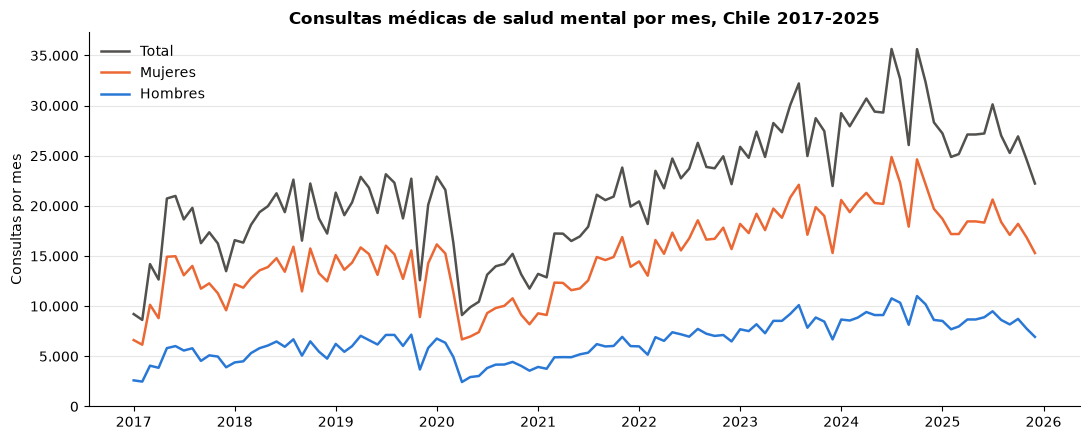

In [16]:
COLORES = {"Total": "#52514e", "Mujeres": "#eb6834", "Hombres": "#2a78d6"}

fig, ax = plt.subplots(figsize=(11, 4.5))
for nombre, color in COLORES.items():
    ax.plot(por_sexo.index, por_sexo[nombre], label=nombre, color=color, linewidth=1.8)

ax.set_title("Consultas médicas de salud mental por mes, Chile 2017-2025", fontweight="bold")
ax.set_ylabel("Consultas por mes")
ax.yaxis.set_major_formatter(miles)
ax.set_ylim(bottom=0)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Consultas por tramo de edad (2024)

Los datos ya cargados traen las columnas `edad| ...; sexo| ...`. Se separa la etiqueta en sus dos
dimensiones y se suma el año.

In [17]:
ANIO = 2024

edad = salud_mental[
    (salud_mental["anio"] == ANIO)
    & salud_mental["nombre_col_numerica"].str.startswith("edad|")
].copy()
edad["tramo"] = edad["nombre_col_numerica"].str.extract(r"edad\| ([^;]+)")[0]
edad["sexo"] = edad["nombre_col_numerica"].str.extract(r"sexo\| (.+)$")[0].str.capitalize()

# Orden de los tramos: el mismo de las columnas del formulario
orden = edad.drop_duplicates("tramo").sort_values("nombre_col_numerica", key=lambda s: s.map(
    dict(zip(cols_sm["nombre_col_numerica"], cols_sm["cod_col_numerica"]))
))["tramo"].tolist()
por_edad = (
    edad.pivot_table(index="tramo", columns="sexo", values="cantidad", aggfunc="sum")
    .reindex(orden)[["Mujeres", "Hombres"]]
)
por_edad.astype(int).T

tramo,menor de 1 año,1-4 años,5-9 años,10-14 años,15-19 años,20-24 años,25-29 años,30-34 años,35-39 años,40-44 años,45-49 años,50-54 años,55-59 años,60-64 años,65-69 años,70-74 años,75-79 años,80 años o más
sexo,,,,,,,,,,,,,,,,,,
Mujeres,0,1630,5419,12132,15910,14362,19225,23286,21392,19083,17247,18903,19179,18191,14541,11278,9479,12466
Hombres,0,3566,10269,10604,9686,6291,7042,7579,7175,6552,5958,6217,6056,6453,5444,4544,3936,5389


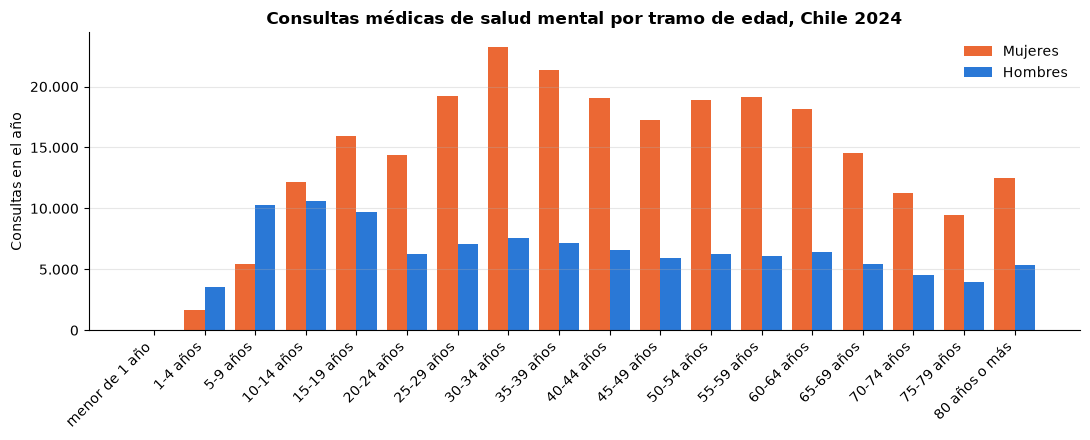

In [18]:
fig, ax = plt.subplots(figsize=(11, 4.5))
x = range(len(por_edad))
ancho = 0.4
ax.bar([i - ancho / 2 for i in x], por_edad["Mujeres"], width=ancho,
       label="Mujeres", color=COLORES["Mujeres"])
ax.bar([i + ancho / 2 for i in x], por_edad["Hombres"], width=ancho,
       label="Hombres", color=COLORES["Hombres"])

ax.set_xticks(list(x))
ax.set_xticklabels(por_edad.index, rotation=45, ha="right")
ax.set_title(f"Consultas médicas de salud mental por tramo de edad, Chile {ANIO}",
             fontweight="bold")
ax.set_ylabel("Consultas en el año")
ax.yaxis.set_major_formatter(miles)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

---
## 5. Caso 2: entrega de leche del PNAC

Pregunta: **¿a cuántas personas les entrega leche cada mes el Programa Nacional de Alimentación
Complementaria (PNAC)?**

Mismos 5 pasos, con otra palabra.

### Paso 1: ¿dónde aparece "leche"?

In [19]:
buscar("leche")

,cod_hoja,nombre_hoja,nombre_seccion,coincidencias,ejemplo
0,a11a,transmisión vertical materno infantil,recién nacidos expuestos al vih que reciben leche maternizada al alta,4,tipo de movimiento| recién nacidos vivos hijos de mujer con serología vih (+) no confirmada por el isp
1,d15,programa nacional de alimentación complementaria (pnac),pnac - cantidad distribuida (kg) a personas intrasistema,14,tipo de movimiento| productos; producto| leche purita fortificada (lpf); producto| fórmula de inicio (fi)
2,d15,programa nacional de alimentación complementaria (pnac),pnac - número de personas extrasistema que retiran,1,subprograma| alergia a la proteína de la leche de vaca
3,d15,programa nacional de alimentación complementaria (pnac),pnac - número de personas intrasistema que retiran,1,subprograma| alergia a la proteína de la leche de vaca
4,d15,programa nacional de alimentación complementaria (pnac),pnac: cantidad distribuida (kg) a personas extrasistema (incluye modalidad libre elección),14,tipo de movimiento| productos; producto| leche purita fortificada (lpf); producto| fórmula de inicio (fi)


Casi todo cae en la hoja **d15**, *programa nacional de alimentación complementaria (pnac)*, que
tiene dos tipos de sección: **cantidad distribuida (kg)** y **número de personas que retiran**,
cada una para personas intrasistema (beneficiarias de la red pública) y extrasistema. La fila de la
hoja a11a (recién nacidos expuestos al VIH que reciben leche maternizada) es otro tema.

### Paso 2: ¿qué prestaciones tiene la sección de personas que retiran?

Se listan todas las secciones de la hoja d15 y luego las prestaciones de la elegida:

In [20]:
prestaciones("d15")["nombre_seccion"].value_counts().rename("prestaciones").to_frame()

,prestaciones
nombre_seccion,
pnac - cantidad distribuida (kg) a personas intrasistema,14
pnac: cantidad distribuida (kg) a personas extrasistema (incluye modalidad libre elección),14
pnac - número de personas extrasistema que retiran,5
pnac - número de personas intrasistema que retiran,5


In [21]:
LECHE_HOJA = "d15"
LECHE_SECCION = "pnac - número de personas intrasistema que retiran"

prestaciones(LECHE_HOJA, seccion=LECHE_SECCION)

,nombre_seccion,nombre_prestacion,cod_prestacion
0,pnac - número de personas intrasistema que retiran,subprograma| alergia a la proteína de la leche de vaca,15900050
1,pnac - número de personas intrasistema que retiran,subprograma| básico,15050100
2,pnac - número de personas intrasistema que retiran,subprograma| prematuros,15050500
3,pnac - número de personas intrasistema que retiran,subprograma| programas sociales,15900060
4,pnac - número de personas intrasistema que retiran,subprograma| refuerzo,15050200


Cada prestación es un **subprograma** del PNAC (básico, refuerzo, prematuros, alergia a la proteína
de la leche de vaca, programas sociales). Como interesa el total del programa, no se elige una
prestación: se pasa `prestacion=None` y se suman todas.

> Las secciones en **kg** tienen una fila por producto (leche purita fortificada, fórmula de inicio,
> purita mamá...), pero algunos productos aparecen con más de un código y la misma etiqueta. Para
> un primer análisis, el número de personas es más directo.

### Paso 3: ¿qué cortes trae?

In [22]:
cols_leche = columnas_de(LECHE_HOJA, LECHE_SECCION)
print(cols_leche["dimensiones"].value_counts().to_string())
cols_leche

dimensiones
grupo poblacional, edad                   7
grupo poblacional, estado de lactancia    3
sexo                                      2
grupo poblacional, estado_nutricional     2
tipo de conteo                            1


,cod_col_numerica,nombre_col_numerica,dimensiones
0,col01,tipo de conteo| total,tipo de conteo
1,col02,sexo| hombres,sexo
2,col03,sexo| mujeres,sexo
3,col04,grupo poblacional| menores a 6 años; edad| 0-2 meses,"grupo poblacional, edad"
4,col05,grupo poblacional| menores a 6 años; edad| 3-5 meses,"grupo poblacional, edad"
5,col06,grupo poblacional| menores a 6 años; edad| 6-11 meses,"grupo poblacional, edad"
6,col07,grupo poblacional| menores a 6 años; edad| 12-17 meses,"grupo poblacional, edad"
7,col08,grupo poblacional| menores a 6 años; edad| 18-23 meses,"grupo poblacional, edad"
8,col09,grupo poblacional| menores a 6 años; edad| 24-47 meses,"grupo poblacional, edad"
9,col10,grupo poblacional| menores a 6 años; edad| 48-71 meses,"grupo poblacional, edad"


Total, sexo, edad de los menores de 6 años, gestantes según estado nutricional y personas que
amamantan según lactancia.

### Paso 4: ¿para qué años existe?

In [23]:
anios_disponibles(LECHE_HOJA, LECHE_SECCION)

,anio,prestaciones,columnas
0,2017,5,13
1,2018,5,13
2,2019,5,13
3,2020,5,13
4,2021,5,13
5,2022,5,15
6,2023,5,15
7,2024,5,15
8,2025,5,15


La sección tiene este nombre desde **2017**. Entre 2009 y 2016 la hoja d15 existía con otros nombres
de sección (*número de personas beneficiarias del s.n.s.s*); para extender la serie hacia atrás
habría que repetir el paso 2 en esos años (`prestaciones("d15", anio=2015)`).

### Paso 5: traer la serie (1-2 minutos)

In [24]:
leche = serie(LECHE_HOJA, LECHE_SECCION, desde=2017, hasta=2025)
print(f"Filas: {len(leche):,} (mes × subprograma × columna)")
leche.head()

Filas: 5,728 (mes × subprograma × columna)


,anio,mes,nombre_prestacion,nombre_col_numerica,cantidad,fecha
0,2017,1,subprograma| alergia a la proteína de la leche de vaca,grupo poblacional| menores a 6 años; edad| 0-2 meses,6.0,2017-01-01
1,2017,1,subprograma| alergia a la proteína de la leche de vaca,grupo poblacional| menores a 6 años; edad| 12-17 meses,57.0,2017-01-01
2,2017,1,subprograma| alergia a la proteína de la leche de vaca,grupo poblacional| menores a 6 años; edad| 18-23 meses,19.0,2017-01-01
3,2017,1,subprograma| alergia a la proteína de la leche de vaca,grupo poblacional| menores a 6 años; edad| 3-5 meses,24.0,2017-01-01
4,2017,1,subprograma| alergia a la proteína de la leche de vaca,grupo poblacional| menores a 6 años; edad| 6-11 meses,50.0,2017-01-01


### Personas que retiran por mes, por subprograma

In [25]:
total_leche = (
    leche[leche["nombre_col_numerica"] == "tipo de conteo| total"]
    .assign(subprograma=lambda d: d["nombre_prestacion"].str.replace("subprograma| ", "", regex=False))
    .pivot_table(index="fecha", columns="subprograma", values="cantidad", aggfunc="sum")
)
# Promedio mensual por año (las personas retiran todos los meses: sumar meses las contaría varias veces)
# (<NA> = el subprograma no existía ese año)
total_leche.groupby(total_leche.index.year).mean().round().astype("Int64")

subprograma,alergia a la proteína de la leche de vaca,básico,prematuros,prematuros extremos,programas sociales,refuerzo
fecha,,,,,,
2017,426,431935,<NA>,2376,116,13102
2018,761,432076,<NA>,2397,150,12952
2019,1405,420586,<NA>,2523,280,12330
2020,1909,356765,<NA>,2189,91,9826
2021,1999,273766,<NA>,2298,79,6184
2022,2398,283003,1406,<NA>,145,6726
2023,2893,331613,1373,<NA>,26,8916
2024,3317,345299,1253,<NA>,18,9547
2025,3867,331146,1149,<NA>,23,9218


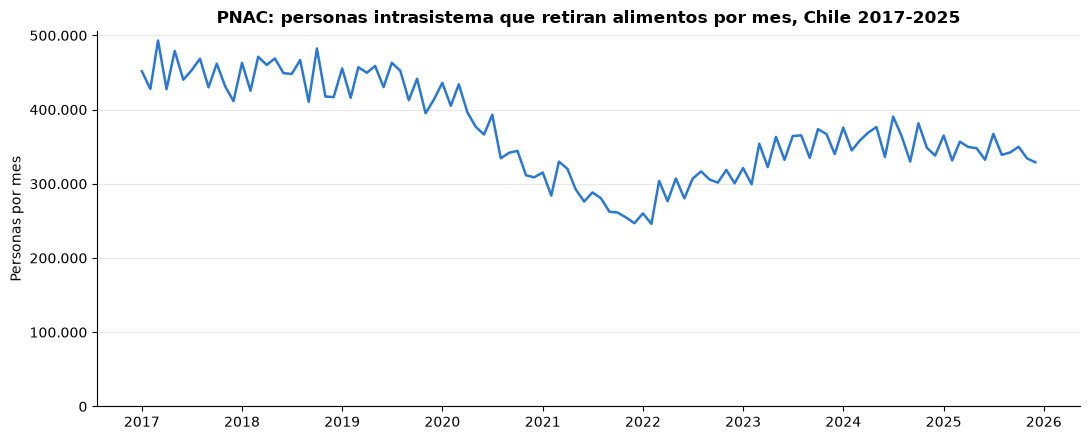

In [26]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(total_leche.index, total_leche.sum(axis=1), color="#2a78d6", linewidth=1.8)

ax.set_title("PNAC: personas intrasistema que retiran alimentos por mes, Chile 2017-2025",
             fontweight="bold")
ax.set_ylabel("Personas por mes")
ax.yaxis.set_major_formatter(miles)
ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

El subprograma **básico** concentra casi todo; los demás (refuerzo, prematuros, alergia) suman
unas pocas decenas de miles de personas al mes. En la tabla anual se ve otro cambio de etiqueta:
*prematuros extremos* (hasta 2021) pasa a llamarse *prematuros* desde 2022. Al sumar toda la
sección no importa, pero si se elige un subprograma por nombre hay que unir ambas etiquetas.

### ¿Quiénes retiran? (promedio mensual 2024)

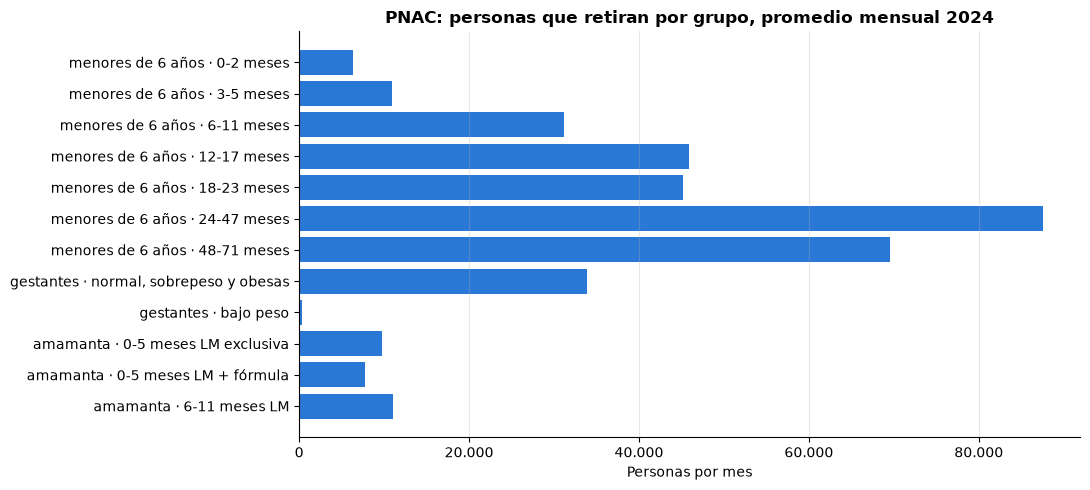

In [27]:
grupos = (
    leche[(leche["anio"] == ANIO) & leche["nombre_col_numerica"].str.startswith("grupo poblacional|")]
    .groupby(["mes", "nombre_col_numerica"])["cantidad"].sum()   # suma de subprogramas
    .groupby("nombre_col_numerica").mean()                       # promedio de los 12 meses
)
# Orden del formulario y etiqueta corta: "menores de 6 años · 0-2 meses", "gestantes · bajo peso", ...
grupos = grupos.reindex(
    [e for e in cols_leche["nombre_col_numerica"] if e.startswith("grupo poblacional|")]
)
CORTOS = {
    "menores a 6 años": "menores de 6 años",
    "persona que amamanta a hijo/a menor a 12 meses": "amamanta",
    "lactancia materna": "LM",
    "fórmula láctea": "fórmula",
    "con LM exclusiva": "LM exclusiva",
}
def etiqueta_corta(e):
    texto = " · ".join(p.split("| ", 1)[1] for p in e.split("; "))
    for largo, corto in CORTOS.items():
        texto = texto.replace(largo, corto)
    return texto
grupos.index = [etiqueta_corta(e) for e in grupos.index]

fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(grupos.index, grupos.values, color="#2a78d6")
ax.invert_yaxis()
ax.set_title(f"PNAC: personas que retiran por grupo, promedio mensual {ANIO}", fontweight="bold")
ax.set_xlabel("Personas por mes")
ax.xaxis.set_major_formatter(miles)
ax.grid(axis="x", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

---
## 6. Tu propia búsqueda

Cambia `TEXTO` y ejecuta las celdas en orden. Cada paso te da el valor para el siguiente.

In [28]:
TEXTO = "diabetes"  # palabra a buscar

buscar(TEXTO)

,cod_hoja,nombre_hoja,nombre_seccion,coincidencias,ejemplo
0,a05,ingresos y egresos por condición y problemas de salud,egresos del pscv,1,tipo de total| programa de salud cardiovascular; tipo| diabetes mellitus
1,a05,ingresos y egresos por condición y problemas de salud,ingreso de gestantes con patología de alto riesgo obstétrico a la unidad de aro (nivel secundario),2,diagnóstico| diabetes
2,a05,ingresos y egresos por condición y problemas de salud,ingresos al pscv,1,tipo de total| programa de salud cardiovascular; tipo| diabetes mellitus
3,a07,atención de especialidades,atenciones médicas por programas y policlínicos (incluidas en sección a),1,atención| diabetes
4,a28,rehabilitación integral,"ayudas técnicas de salud, nivel aps y hospitalario",1,total ayuda técnica por condición de salud| diabetes mellitus
5,a29,programa de imágenes diagnósticas y/o resolutividad en atención primaria,fondos de ojo control diabetes mellitus,9,prestacion| entrega resultados fondo de ojo al usuario; categoria| presencial
6,a29,programa de imágenes diagnósticas y/o resolutividad en atención primaria,procedimientos apoyo clínico y terapéutico,2,"subcategoria| oftalmología; prestacion| exploración vitreorretinal, pacientes sin diabetes mellitus"
7,b,NaN,inmunología,1,procedimiento| estudio inmunológico de diabetes (incluye determinación simultánea de anticuerpos anti-células de isl...
8,bm18,actividades de apoyo diagnostico y terapeutico (uso exclusivo de establecimientos municipales),misceláneos,1,misceláneos| autocontrol personas con diabetes insulino dependiente (d.i.d. mensual)
9,p1,población en control programa de salud de la mujer,población en control por patologías de alto riesgo obstétrico,2,diagnóstico| diabetes gestacional


In [29]:
# Paso 2: copia un cod_hoja de la tabla anterior
MI_HOJA = "p4"
prestaciones(MI_HOJA, texto=TEXTO)

,nombre_seccion,nombre_prestacion,cod_prestacion
0,metas de compensación,tipo de total| personas bajo control por diabetes mellitus; tipo| hba1c menor a 7%,p4180300
1,metas de compensación,tipo de total| personas bajo control por diabetes mellitus; tipo| hba1c menor a 7% - pa menor a 140/90 mmhg y colest...,p4190920
2,metas de compensación,tipo de total| personas bajo control por diabetes mellitus; tipo| hba1c menor a 8%,p4200200
3,programa salud cardiovascular (pscv),tipo de total| personas bajo control según patología y factores de riesgo (existencia); total de ayuda técnica por c...,p4150602
4,variables de seguimiento del pscv al corte,tipo de validacion| variables; población| personas con diabetes en pscv; total de beneficiarios| con atención podoló...,p4200600
5,variables de seguimiento del pscv al corte,tipo de validacion| variables; población| personas con diabetes en pscv; total de beneficiarios| con diagnóstico aso...,p4200900
6,variables de seguimiento del pscv al corte,tipo de validacion| variables; población| personas con diabetes en pscv; total de beneficiarios| con diagnóstico de ...,p4301070
7,variables de seguimiento del pscv al corte,tipo de validacion| variables; población| personas con diabetes en pscv; total de beneficiarios| con ecg vigente,p4200300
8,variables de seguimiento del pscv al corte,tipo de validacion| variables; población| personas con diabetes en pscv; total de beneficiarios| con erc etapa 3b o ...,p4190807
9,variables de seguimiento del pscv al corte,tipo de validacion| variables; población| personas con diabetes en pscv; total de beneficiarios| con evaluación vige...,p4190500


In [30]:
# Pasos 3 y 4: copia la sección (y si quieres, la prestación) de la tabla anterior
MI_SECCION = "metas de compensación"
MI_PRESTACION = None  # None = todas las prestaciones de la sección

mis_columnas = columnas_de(MI_HOJA, MI_SECCION, MI_PRESTACION)
display(mis_columnas)
anios_disponibles(MI_HOJA, MI_SECCION, MI_PRESTACION)

,cod_col_numerica,nombre_col_numerica,dimensiones
0,col01,tipo de conteo| total; sexo| ambos sexos,"tipo de conteo, sexo"
1,col02,tipo de conteo| total; sexo| hombres,"tipo de conteo, sexo"
2,col03,tipo de conteo| total; sexo| mujeres,"tipo de conteo, sexo"
3,col04,edad| 15-19 años; sexo| hombres,"edad, sexo"
4,col05,edad| 15-19 años; sexo| mujeres,"edad, sexo"
5,col06,edad| 20-24 años; sexo| hombres,"edad, sexo"
6,col07,edad| 20-24 años; sexo| mujeres,"edad, sexo"
7,col08,edad| 25-29 años; sexo| hombres,"edad, sexo"
8,col09,edad| 25-29 años; sexo| mujeres,"edad, sexo"
9,col10,edad| 30-34 años; sexo| hombres,"edad, sexo"


,anio,prestaciones,columnas
0,2010,4,15
1,2011,4,15
2,2012,6,19
3,2013,6,19
4,2014,6,33
5,2015,6,35
6,2016,6,35
7,2017,8,35
8,2018,8,35
9,2019,8,35


In [31]:
# Paso 5: lee la tabla de hechos. Un año tarda menos de un minuto; varios años, 1-2 minutos.
# La hoja p4 es de la serie P (población en control): se reporta solo en junio y diciembre.
mi_serie = serie(MI_HOJA, MI_SECCION, MI_PRESTACION, desde=2024, hasta=2024)
# Quedarse con una sola columna (col01 suele ser el total): sumar todas mezclaría total, sexo y edad
MI_COLUMNA = mis_columnas["nombre_col_numerica"].iloc[0]
print(f"Columna: {MI_COLUMNA}")
(
    mi_serie[mi_serie["nombre_col_numerica"] == MI_COLUMNA]
    .pivot_table(index="nombre_prestacion", columns="mes", values="cantidad", aggfunc="sum")
    .astype("Int64")
)

Columna: tipo de conteo| total; sexo| ambos sexos


mes,6,12
nombre_prestacion,,
tipo de total| personas bajo control con antecedentes enfermedad cardiovascular (ecv); tipo| en tratamiento con antiagregantes plaquetarios,110947,114736
tipo de total| personas bajo control con antecedentes enfermedad cardiovascular (ecv); tipo| en tratamiento con estatina,135221,142257
tipo de total| personas bajo control con antecedentes enfermedad cardiovascular (ecv); tipo| fumador actual,100796,103722
tipo de total| personas bajo control por diabetes mellitus; tipo| hba1c menor a 7%,382088,405887
tipo de total| personas bajo control por diabetes mellitus; tipo| hba1c menor a 7% - pa menor a 140/90 mmhg y colesterol ldl menor a 100 mg/dl,190251,207606
tipo de total| personas bajo control por diabetes mellitus; tipo| hba1c menor a 8%,86142,94069
tipo de total| personas bajo control por hipertensión; tipo| pa menor a 140/90 mmhg,1069552,1139610
tipo de total| personas bajo control por hipertensión; tipo| pa menor a 150/90 mmhg,230191,245859
tipo de total| personas con rcv alto; criterio| colesterol ldl menor a 100 mg/dl,622858,674166


### Notas

- `cantidad` es lo que reporta cada establecimiento; para totales nacionales basta con `SUM`. Para
  cortes por establecimiento, agregar `id_establecimiento` al `GROUP BY` de `serie`.
- Algunas columnas cuentan **personas en un mes** (como el PNAC): sumarlas a lo largo de los meses
  cuenta a la misma persona varias veces; usar promedios o meses puntuales.
- Las etiquetas pueden cambiar entre años (DEIS modifica el formulario): revisar siempre
  `anios_disponibles` antes de armar una serie larga.
- Filtrar siempre por `anio` (partición) y `cod_prestacion`: la tabla completa tiene ~1.900
  millones de filas.
- En v1, los códigos con letras están en minúscula en `codigos` y en mayúscula en `hechos` (toda la
  serie P, algunos de la serie A): cruzar con `lower(cod_prestacion)`, como hace `serie`.
- La serie **BS** está casi sin cubrir en `codigos` (en 2024, ~200 de ~3.100 códigos tienen
  etiqueta): sus datos están en `hechos`, pero no se pueden encontrar por texto.

---

*Datos provistos por [Data Observatory](https://dataobservatory.net) · Fuente: DEIS, Ministerio de Salud de Chile*